In [1]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/Damage Propagation Modeling.pdf
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/RUL_FD001.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/RUL_FD002.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/RUL_FD003.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/RUL_FD004.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/readme.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/test_FD001.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/test_FD002.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/test_FD003.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation/test_FD004.txt
/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degrad

In [2]:
import os
import pandas as pd
import numpy as np

DATA_PATH = '/kaggle/input/datasets/bishals098/nasa-turbofan-engine-degradation-simulation'

cols = ['unit', 'cycle', 'op1', 'op2', 'op3'] + [f's{i}' for i in range(1, 22)]

train = pd.read_csv(os.path.join(DATA_PATH, 'train_FD001.txt'), sep=r'\s+', header=None, names=cols)
test = pd.read_csv(os.path.join(DATA_PATH, 'test_FD001.txt'), sep=r'\s+', header=None, names=cols)
true_rul = pd.read_csv(os.path.join(DATA_PATH, 'RUL_FD001.txt'), header=None, names=['RUL'])

print(train.shape, test.shape, true_rul.shape)
print('Train engines:', train['unit'].nunique())
print('Test engines:', test['unit'].nunique())

life = train.groupby('unit')['cycle'].max()
print(life.describe())

train.head()

(20631, 26) (13096, 26) (100, 1)
Train engines: 100
Test engines: 100
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
# 1. Create RUL for each training row
train['RUL'] = train.groupby('unit')['cycle'].transform('max') - train['cycle']
train['RUL'] = train['RUL'].clip(upper=125)

# 2. Find sensors that never change (useless for the model)
sensor_cols = [f's{i}' for i in range(1, 22)]
constant = [c for c in sensor_cols if train[c].std() == 0]
print('Constant sensors (dropped):', constant)

# 3. Keep only sensors that change
sensors = [c for c in sensor_cols if c not in constant]
print('Sensors used:', len(sensors), sensors)

# 4. Check one engine: first and last rows
print(train[train['unit'] == 1][['cycle', 'RUL']].iloc[[0, 100, -1]])

Constant sensors (dropped): ['s18', 's19']
Sensors used: 19 ['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's20', 's21']
     cycle  RUL
0        1  125
100    101   91
191    192    0


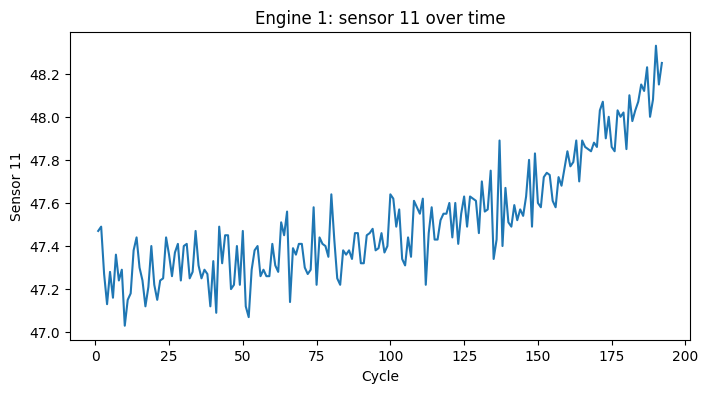

In [5]:
import matplotlib.pyplot as plt

e1 = train[train['unit'] == 1]
plt.figure(figsize=(8, 4))
plt.plot(e1['cycle'], e1['s11'])
plt.xlabel('Cycle')
plt.ylabel('Sensor 11')
plt.title('Engine 1: sensor 11 over time')
plt.show()

In [6]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# 1. Fix the constant-sensor check
sensor_cols = [f's{i}' for i in range(1, 22)]
constant = [c for c in sensor_cols if train[c].std() < 1e-6]
sensors = [c for c in sensor_cols if c not in constant]
print('Dropped:', constant)
print('Kept:', len(sensors))

# 2. Add rolling-average features (smooths the noise), separately for each engine
def add_features(df, sensors, window=5):
    df = df.sort_values(['unit', 'cycle']).copy()
    roll = (df.groupby('unit')[sensors]
              .rolling(window, min_periods=1).mean()
              .reset_index(level=0, drop=True))
    roll.columns = [c + '_avg' for c in sensors]
    return pd.concat([df, roll], axis=1)

train_f = add_features(train, sensors)
features = sensors + [c + '_avg' for c in sensors]

# 3. Split by ENGINE (not by row): 80 engines to train, 20 to validate
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, va_idx = next(gss.split(train_f, groups=train_f['unit']))
tr, va = train_f.iloc[tr_idx], train_f.iloc[va_idx]
print('Train engines:', tr['unit'].nunique(), '| Validation engines:', va['unit'].nunique())

# 4. Train two models and compare
def rmse(y, p):
    return np.sqrt(mean_squared_error(y, p))

lr = LinearRegression().fit(tr[features], tr['RUL'])
print('Linear Regression RMSE:', round(rmse(va['RUL'], lr.predict(va[features])), 2))

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(tr[features], tr['RUL'])
print('Random Forest RMSE:', round(rmse(va['RUL'], rf.predict(va[features])), 2))

Dropped: ['s1', 's5', 's10', 's16', 's18', 's19']
Kept: 15
Train engines: 80 | Validation engines: 20
Linear Regression RMSE: 19.85
Random Forest RMSE: 16.61


In [7]:
# 1. Retrain the final model on ALL 100 training engines
rf_final = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_final.fit(train_f[features], train_f['RUL'])

# 2. Build the same features for the test engines, take the LAST row of each engine
test_f = add_features(test, sensors)
last = test_f.groupby('unit').tail(1).sort_values('unit').reset_index(drop=True)

# 3. Predict and compare with the true RUL (same cap of 125)
pred = rf_final.predict(last[features])
true = true_rul['RUL'].clip(upper=125).values
print('Test RMSE (last row of each engine):', round(rmse(true, pred), 2))

# 4. Build the decision table
fleet = pd.DataFrame({
    'engine': last['unit'].values,
    'predicted_rul': pred.round(0).astype(int),
    'true_rul': true
})
fleet['risk'] = pd.cut(fleet['predicted_rul'], bins=[-1, 30, 80, 1000],
                       labels=['Critical', 'Warning', 'Healthy'])
fleet = fleet.sort_values('predicted_rul').reset_index(drop=True)

print(fleet['risk'].value_counts())
fleet.head(10)

Test RMSE (last row of each engine): 18.53
risk
Healthy     57
Warning     25
Critical    18
Name: count, dtype: int64


,engine,predicted_rul,true_rul,risk
0,34,5,7,Critical
1,81,7,8,Critical
2,35,9,11,Critical
3,31,11,8,Critical
4,68,11,8,Critical
5,76,11,10,Critical
6,82,13,9,Critical
7,56,13,15,Critical
8,66,16,14,Critical
9,92,17,20,Critical


In [8]:
# How many engines are placed in the right risk group?
fleet['true_risk'] = pd.cut(fleet['true_rul'], bins=[-1, 30, 80, 1000],
                            labels=['Critical', 'Warning', 'Healthy'])
print((fleet['risk'] == fleet['true_risk']).mean())
print(pd.crosstab(fleet['true_risk'], fleet['risk']))

0.81
risk       Critical  Warning  Healthy
true_risk                            
Critical         17        8        0
Warning           1       13        6
Healthy           0        4       51


In [9]:
true_crit = fleet['true_rul'] <= 30
total_crit = true_crit.sum()

print('Cut-off | Critical caught | False alarms')
for t in [20, 30, 40, 50, 60]:
    flagged = fleet['predicted_rul'] <= t
    caught = (flagged & true_crit).sum()
    false_alarm = (flagged & ~true_crit).sum()
    print(f'  {t:>3}   |   {caught:>2} / {total_crit}       |     {false_alarm}')

Cut-off | Critical caught | False alarms
   20   |   16 / 25       |     1
   30   |   17 / 25       |     1
   40   |   21 / 25       |     2
   50   |   23 / 25       |     7
   60   |   23 / 25       |     11


In [10]:
CRIT, WARN = 30, 80      # change CRIT after you look at the table above

fleet['risk'] = pd.cut(fleet['predicted_rul'], bins=[-1, CRIT, WARN, 1000],
                       labels=['Critical', 'Warning', 'Healthy'])
fleet = fleet.sort_values('predicted_rul').reset_index(drop=True)
fleet[['engine', 'predicted_rul', 'risk']].to_csv('/kaggle/working/fleet.csv', index=False)
print(fleet['risk'].value_counts())

risk
Healthy     57
Warning     25
Critical    18
Name: count, dtype: int64


In [11]:
CRIT, WARN = 40, 80

fleet['risk'] = pd.cut(fleet['predicted_rul'], bins=[-1, CRIT, WARN, 1000],
                       labels=['Critical', 'Warning', 'Healthy'])
fleet = fleet.sort_values('predicted_rul').reset_index(drop=True)
fleet[['engine', 'predicted_rul', 'risk']].to_csv('/kaggle/working/fleet.csv', index=False)
print(fleet['risk'].value_counts())

risk
Healthy     57
Critical    23
Warning     20
Name: count, dtype: int64
